# EMQA_L2_arx_coef

**The ARX coefficients change with the hour of the day**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_arx_coef/EMQA_L2_arx_coef.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Panels of price, load and wind + solar

In [4]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO"])
PM, DST = day_matrix(HP["RO"].dropna())
CAL = pd.date_range(START, END, freq="D")
PM, DST = PM.reindex(CAL), DST.reindex(CAL)
GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "load", "wind_onshore", "solar"])
LM, _ = day_matrix(GH["load"].dropna())
RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
LM, RM = LM.reindex(CAL), RM.reindex(CAL)
assert not PM.isna().any().any() and not LM.isna().any().any() and not RM.isna().any().any(), "panel has gaps"
L_, R_ = LM.values.astype(float), RM.values.astype(float)
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
TI_ROWS = np.array([IDX[t] for t in TDAYS])              # panel rows of the test days
A = P_[TI_ROWS]                                          # actual prices of the test year, days x 24
# naive benchmark: same hour of d-7 on Monday, Saturday, Sunday, of d-1 otherwise
NAIVE = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in TI_ROWS])
print("panel:", CAL[0].date(), "to", CAL[-1].date(), len(CAL), "days x 24 hours")

panel: 2022-01-01 to 2026-10-31 1765 days x 24 hours


## Expert ARX(728), re-estimated every day of the test year (one OLS regression per hour)

In [5]:
from scipy import stats


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def arx_day(Pa, La, Ra, Fa, i, T, kind="asinh"):
    """Expert ARX (Assignment 1, Ziel & Weron 2018 style), one regression per hour; target day = row i.
    Calibration targets rows i-T..i-1; VST median/MAD from price rows i-T-7..i-1; L,R z-scores from rows i-T-7..i-2."""
    P1, P2, P7 = shift_rows(Pa, 1), shift_rows(Pa, 2), shift_rows(Pa, 7)
    lo = i - T
    if kind == "raw":
        m, s = 0.0, 1.0
        f = lambda x: x  # noqa: E731
        finv = f
    else:
        m, s = mad_scale(Pa[lo - 7:i])
        f = lambda x: np.arcsinh((x - m) / s)  # noqa: E731
        finv = lambda y: m + s * np.sinh(y)  # noqa: E731
    rows = slice(lo, i + 1)
    Y, Y1, Y2, Y7 = f(Pa[rows]), f(P1[rows]), f(P2[rows]), f(P7[rows])
    mu_l, sd_l = np.mean(La[lo - 7:i - 1]), np.std(La[lo - 7:i - 1])
    mu_r, sd_r = np.mean(Ra[lo - 7:i - 1]), np.std(Ra[lo - 7:i - 1])
    Lz = (shift_rows(La, 2)[rows] - mu_l) / sd_l
    Rz = (shift_rows(Ra, 2)[rows] - mu_r) / sd_r
    dw = DOW[rows]
    dmy = np.column_stack([dw == 0, dw == 5, dw == 6]).astype(float)
    extra = None
    if kind == "fund":
        Fr = Fa[rows]
        extra = (Fr - np.nanmean(Fr[:-1], axis=0)) / np.nanstd(Fr[:-1], axis=0)
    n = T + 1
    out, coefs = np.zeros(24), np.zeros((24, 12))
    if kind == "single":                                          # one pooled regression, common slopes, hour intercepts
        Xs, ys = [], []
        for h in range(24):
            hd = np.zeros((n, 24))
            hd[:, h] = 1
            Xs.append(np.column_stack([hd, Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1), Lz[:, h], Rz[:, h], dmy]))
            ys.append(Y[:, h])
        Xs, ys = np.stack(Xs, 1), np.stack(ys, 1)                 # n x 24 x p
        Xc, yc = Xs[:-1].reshape(-1, Xs.shape[2]), ys[:-1].ravel()
        b = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        return finv(Xs[-1] @ b), None
    for h in range(24):
        cols = [np.ones(n), Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1)]
        if kind != "noexog":
            cols += [Lz[:, h], Rz[:, h]]
        cols += [dmy[:, 0], dmy[:, 1], dmy[:, 2]]
        X = np.column_stack(cols)
        if h == 23:
            X = np.delete(X, 4, axis=1)                           # Y_{d-1,23} appears twice for h = 23
        if extra is not None:
            X = np.column_stack([X, extra])
        b = np.linalg.lstsq(X[:-1], Y[:-1, h], rcond=None)[0]
        out[h] = X[-1] @ b
        if kind == "asinh" and h != 23 and X.shape[1] == 12:
            coefs[h] = b
    return finv(out), coefs

In [6]:
CO = np.array([arx_day(P_, L_, R_, None, i, 728)[1] for i in TI_ROWS])   # days x 24 hours x 12 coefficients
coef_mean = CO.mean(0)
CNAMES = ["const", "Y1", "Y2", "Y7", "Y1_23", "Ymin", "Ymax", "L", "R", "Mon", "Sat", "Sun"]
# hour 23 has one regressor less (Y(d-1,23) would appear twice), so it is left out, as on the slide
print(pd.DataFrame(coef_mean[:23], columns=CNAMES).round(3).to_string())

    const     Y1     Y2     Y7  Y1_23   Ymin   Ymax      L      R    Mon    Sat    Sun
0  -0.064  0.079  0.051  0.034  0.733  0.045  0.008  0.002  0.001 -0.019  0.084 -0.023
1  -0.097  0.090  0.069  0.021  0.680  0.062 -0.017  0.031  0.003 -0.041  0.040 -0.046
2  -0.117  0.113  0.078  0.024  0.619  0.069 -0.037  0.021 -0.001 -0.059  0.029 -0.068
3  -0.123  0.117  0.083  0.024  0.604  0.069 -0.045  0.016 -0.002 -0.059 -0.002 -0.088
4  -0.077  0.127  0.116  0.035  0.561  0.056 -0.034  0.028  0.007 -0.022 -0.064 -0.154
5   0.052  0.196  0.101  0.096  0.456  0.049  0.001  0.040  0.006  0.184 -0.259 -0.328
6   0.202  0.306  0.036  0.181  0.270  0.106  0.062  0.022  0.003  0.570 -0.515 -0.515
7   0.323  0.391  0.038  0.211  0.180  0.192  0.043 -0.007  0.000  0.825 -0.618 -0.547
8   0.254  0.399  0.061  0.203  0.105  0.262  0.053 -0.011  0.005  0.826 -0.523 -0.500
9   0.212  0.410  0.089  0.185  0.080  0.302  0.021 -0.008  0.003  0.686 -0.471 -0.379
10  0.112  0.441  0.125  0.165  0.064  0.26

## The chart

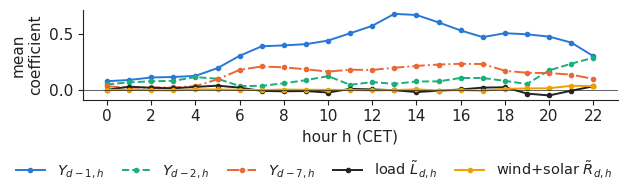

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 2.0))
hh = np.arange(23)
for j, c, lab, ls in [(1, PAL["RO"], "$Y_{d-1,h}$", "-"), (2, PAL["HU"], "$Y_{d-2,h}$", "--"), (3, PAL["DE_LU"], "$Y_{d-7,h}$", "-."),
                      (7, "#222222", "load $\\tilde L_{d,h}$", "-"), (8, PAL["BG"], "wind+solar $\\tilde R_{d,h}$", "-")]:
    ax.plot(hh, coef_mean[:23, j], color=c, ls=ls, marker="o", ms=3, label=lab)
ax.axhline(0, color="#222222", lw=0.5)
ax.set_xticks(range(0, 23, 2))
ax.set_xlabel("hour h (CET)")
ax.set_ylabel("mean\ncoefficient")
legend_bottom(fig, ncol=5)
fig.tight_layout(rect=(0, 0.16, 1, 1))
plt.savefig('arx_coef.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [8]:
print("Numbers on the slide")
print(f'  hour of the largest Y(d-1,h) coefficient: {int(np.argmax(coef_mean[:23, 1])):d}')
print(f'  largest Y(d-1,h) coefficient: {coef_mean[:23, 1].max():.3f}')
print(f'  hour of the smallest Y(d-1,h) coefficient: {int(np.argmin(coef_mean[:23, 1])):d}')
print(f'  smallest Y(d-1,h) coefficient: {coef_mean[:23, 1].min():.3f}')
print(f'  largest Y(d-1,23) coefficient: {coef_mean[:23, 4].max():.3f}')

Numbers on the slide
  hour of the largest Y(d-1,h) coefficient: 13
  largest Y(d-1,h) coefficient: 0.680
  hour of the smallest Y(d-1,h) coefficient: 0
  smallest Y(d-1,h) coefficient: 0.079
  largest Y(d-1,23) coefficient: 0.733
